# Fashion-MNIST CNN Assignment

This notebook is divided into smaller, step-by-step blocks so you can run each part separately.

Recommended order:
1. Import data
2. Show data
3. Split + preprocess
4. Build baseline CNN
5. Train baseline
6. Evaluate baseline
7. Build stronger CNN
8. Train stronger CNN
9. Evaluate stronger CNN
10. Results table
11. Appendix

You are expected to run each code cell yourself and take screenshots as needed.


## 1) Import libraries

This cell imports the libraries needed for loading the CSV data, building CNN models, and evaluating them.


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2) Import the Fashion-MNIST CSV files

The dataset is already saved as CSV files in the same folder as this notebook.


In [3]:
ROOT = Path.cwd()
train_df = pd.read_csv(ROOT / "fashion-mnist_train.csv")
test_df = pd.read_csv(ROOT / "fashion-mnist_test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Train columns:", list(train_df.columns[:10]), "...")
print("Label column:", train_df.columns[0])


Train shape: (60000, 785)
Test shape: (10000, 785)
Train columns: ['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9'] ...
Label column: label


## 3) Show the data

This cell prints the first rows and the class labels so you can inspect the dataset structure.


In [4]:
display(train_df.head())
display(test_df.head())

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Class names:")
for i, name in enumerate(class_names):
    print(i, name)

print("Train class counts:")
print(pd.Series(train_df["label"]).value_counts().sort_index())
print("Test class counts:")
print(pd.Series(test_df["label"]).value_counts().sort_index())


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Class names:
0 T-shirt/top
1 Trouser
2 Pullover
3 Dress
4 Coat
5 Sandal
6 Shirt
7 Sneaker
8 Bag
9 Ankle boot
Train class counts:
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64
Test class counts:
label
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
9    1000
Name: count, dtype: int64


## 4) Create the train/validation/test split and preprocess

This section performs the fixed split and prepares the images for CNN input.
- Train: 48,000
- Validation: 6,000
- Test: 10,000
- Resize: 28x28 -> 32x32
- Normalize: pixel values to [0, 1]


In [5]:
X_train = train_df.drop(columns=["label"]).values.astype(np.float32).reshape(-1, 28, 28, 1) / 255.0
y_train = train_df["label"].astype(np.int32).values
X_test = test_df.drop(columns=["label"]).values.astype(np.float32).reshape(-1, 28, 28, 1) / 255.0
y_test = test_df["label"].astype(np.int32).values

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=6000, stratify=y_train, random_state=SEED
)

X_tr = tf.image.resize(X_tr, [32, 32], method="bilinear").numpy().astype(np.float32)
X_val = tf.image.resize(X_val, [32, 32], method="bilinear").numpy().astype(np.float32)
X_test = tf.image.resize(X_test, [32, 32], method="bilinear").numpy().astype(np.float32)

print("Train split size:", len(X_tr))
print("Validation split size:", len(X_val))
print("Test size:", len(X_test))
print("Sample shape after resize:", X_tr[0].shape)


Train split size: 54000
Validation split size: 6000
Test size: 10000
Sample shape after resize: (32, 32, 1)


## 5) Build the baseline CNN model

Model 1: a compact CNN with a few convolution blocks and a simple dense head.


In [6]:
def build_baseline_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(32, 32, 1)),
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(10, activation="softmax"),
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

baseline_model = build_baseline_model()
baseline_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 581,450 (2.22 MB)

 Trainable params: 581,450 (2.22 MB)

 Non-trainable params: 0 (0.00 B)

## 6) Train the baseline model

Use Adam, batch size 128, at most 20 epochs, and early stopping based on validation accuracy.


In [7]:
baseline_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=4,
        restore_best_weights=True,
    )
]

baseline_history = baseline_model.fit(
    X_tr,
    y_tr,
    validation_data=(X_val, y_val),
    batch_size=128,
    epochs=20,
    callbacks=baseline_callbacks,
    verbose=1,
)

baseline_best_epoch = np.argmax(baseline_history.history["val_accuracy"]) + 1
baseline_best_val_acc = np.max(baseline_history.history["val_accuracy"])
print("Best baseline validation accuracy:", baseline_best_val_acc)
print("Best baseline epoch:", baseline_best_epoch)


Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 62s 137ms/step - accuracy: 0.7953 - loss: 0.5606 - val_accuracy: 0.8685 - val_loss: 0.3585
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 91ms/step - accuracy: 0.8766 - loss: 0.3429 - val_accuracy: 0.8903 - val_loss: 0.2889
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.8954 - loss: 0.2900 - val_accuracy: 0.9007 - val_loss: 0.2712
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 46s 109ms/step - accuracy: 0.9064 - loss: 0.2559 - val_accuracy: 0.9082 - val_loss: 0.2531
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 43s 103ms/step - accuracy: 0.9158 - loss: 0.2326 - val_accuracy: 0.9125 - val_loss: 0.2450
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 92ms/step - accuracy: 0.9244 - loss: 0.2093 - val_accuracy: 0.9120 - val_loss: 0.2454
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 95ms/step - accuracy: 0.9286 - loss: 0.1949 - val_accuracy: 0.9095 - val_loss: 0.2475
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 39s 91ms/step - accuracy: 0.9348 - loss: 0.1787

## 7) Evaluate the baseline model

This cell computes the final test accuracy and confusion matrix for the baseline CNN.


Baseline test loss: 0.323848158121109
Baseline test accuracy: 0.9226999878883362


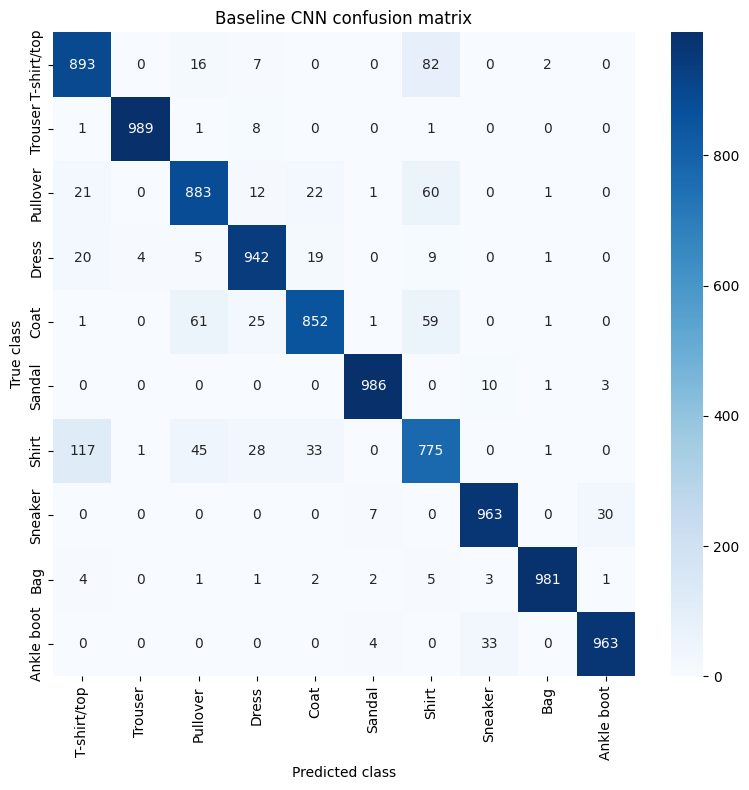

In [8]:
baseline_test_loss, baseline_test_acc = baseline_model.evaluate(X_test, y_test, verbose=0)
baseline_pred = baseline_model.predict(X_test, verbose=0).argmax(axis=1)
baseline_cm = confusion_matrix(y_test, baseline_pred, labels=np.arange(10))

print("Baseline test loss:", baseline_test_loss)
print("Baseline test accuracy:", baseline_test_acc)

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax,
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Baseline CNN confusion matrix")
plt.tight_layout()
plt.show()


## 8) Build the stronger CNN model

Model 2: deeper CNN using BatchNorm, ReLU, and dropout to improve generalization.


In [9]:
def build_stronger_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(32, 32, 1)),
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(256, activation="relu"),
        tf.keras.layers.Dropout(0.4),
        tf.keras.layers.Dense(10, activation="softmax"),
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

stronger_model = build_stronger_model()
stronger_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 815,338 (3.11 MB)

 Trainable params: 814,442 (3.11 MB)

 Non-trainable params: 896 (3.50 KB)

## 9) Train the stronger CNN model

Train with the same optimizer and batch size, using early stopping on validation accuracy.


In [10]:
stronger_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=4,
        restore_best_weights=True,
    )
]

stronger_history = stronger_model.fit(
    X_tr,
    y_tr,
    validation_data=(X_val, y_val),
    batch_size=128,
    epochs=20,
    callbacks=stronger_callbacks,
    verbose=1,
)

stronger_best_epoch = np.argmax(stronger_history.history["val_accuracy"]) + 1
stronger_best_val_acc = np.max(stronger_history.history["val_accuracy"])
print("Best stronger validation accuracy:", stronger_best_val_acc)
print("Best stronger epoch:", stronger_best_epoch)


Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 211s 467ms/step - accuracy: 0.8336 - loss: 0.4783 - val_accuracy: 0.4012 - val_loss: 1.7696
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 272s 645ms/step - accuracy: 0.8931 - loss: 0.2949 - val_accuracy: 0.8958 - val_loss: 0.2828
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 333s 670ms/step - accuracy: 0.9095 - loss: 0.2507 - val_accuracy: 0.9072 - val_loss: 0.2435
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 203s 480ms/step - accuracy: 0.9211 - loss: 0.2159 - val_accuracy: 0.9193 - val_loss: 0.2257
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 243s 576ms/step - accuracy: 0.9286 - loss: 0.1941 - val_accuracy: 0.9080 - val_loss: 0.2534
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 228s 539ms/step - accuracy: 0.9353 - loss: 0.1737 - val_accuracy: 0.9177 - val_loss: 0.2361
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 178s 423ms/step - accuracy: 0.9415 - loss: 0.1555 - val_accuracy: 0.9250 - val_loss: 0.2292
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 180s 426ms/step - accuracy: 0.9470 -

## 10) Evaluate the stronger model

This cell computes the test accuracy and confusion matrix for the stronger CNN.


Stronger test loss: 0.21358540654182434
Stronger test accuracy: 0.9282000064849854


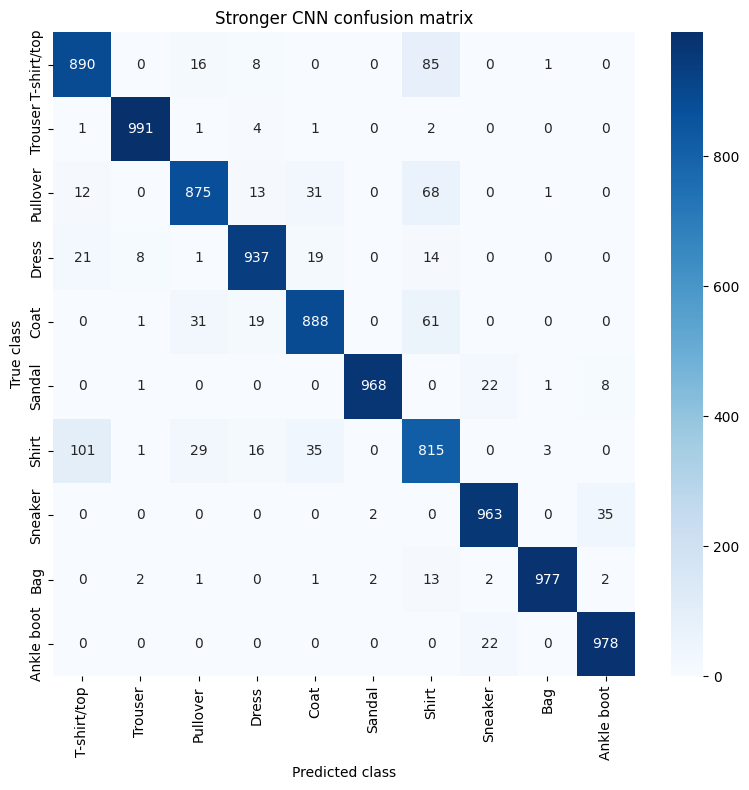

In [11]:
stronger_test_loss, stronger_test_acc = stronger_model.evaluate(X_test, y_test, verbose=0)
stronger_pred = stronger_model.predict(X_test, verbose=0).argmax(axis=1)
stronger_cm = confusion_matrix(y_test, stronger_pred, labels=np.arange(10))

print("Stronger test loss:", stronger_test_loss)
print("Stronger test accuracy:", stronger_test_acc)

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(
    stronger_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax,
)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Stronger CNN confusion matrix")
plt.tight_layout()
plt.show()


## 11) Results table

Fill in the table below with the numbers you obtain after running the models.


In [12]:
results_df = pd.DataFrame({
    "Model": ["User-Defined Baseline", "Stronger CNN"],
    "Best Val Acc": [baseline_best_val_acc, stronger_best_val_acc],
    "Epoch": [baseline_best_epoch, stronger_best_epoch],
    "Test Acc": [baseline_test_acc, stronger_test_acc],
    "Notes": [
        "Small CNN with 2 pooling blocks; quick baseline.",
        "Deeper CNN with BatchNorm + dropout; stronger capacity.",
    ],
})

results_df


,Model,Best Val Acc,Epoch,Test Acc,Notes
0,User-Defined Baseline,0.922167,20,0.9227,Small CNN with 2 pooling blocks; quick baseline.
1,Stronger CNN,0.925000,7,0.9282,Deeper CNN with BatchNorm + dropout; stronger ...


### Short confusion analysis

Write 2–3 lines below after viewing the confusion matrix:

- Example: T-shirt/top and Shirt are often confused because they are visually similar.
- Example: Pullover and Coat may be confused due to similar geometry and shape.
- Example: Sandal and Sneaker may be confused when the silhouette is less distinct.


## 12) Appendix

- Dataset source: Fashion-MNIST by Zalando Research
- Link: https://github.com/zalandoresearch/fashion-mnist
- License: MIT License
- Input resizing: 28x28 -> 32x32
- Fixed train/validation/test split: 48,000 / 6,000 / 10,000
- Class names: T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot
- Augmentation: none used in this notebook so the comparison stays simple and consistent
